In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv("Part_4_Vulnerability_Assessment_and_Remediation_Analysis_new.csv")

In [4]:
df.head(10)

,Asset ID,System Type,Operating System,Vulnerability ID,Severity,Detection Date,Patch Status,Remediation Date,Asset Criticality
0,AST-10001,Cloud Instance,Amazon Linux 2023,CVE-2026-29657,Critical,2026-04-25,PATCHED,2026-05-02,High
1,AST-10002,Web Application,Ubuntu 22.04,CVE-2026-92506,Medium,2026-10-07,pending,2026-12-10,High
2,AST-10003,Database,Windows Server 2019,CVE-2026-17361,High,2026-02-22,NOT PATCHED,2026-03-21,Low
3,AST-10004,Network Device,Cisco IOS,CVE-2026-14238,Medium,05/07/2026,NOT PATCHED,2026-07-28,High
4,AST-10005,Network Device,FortiOS,CVE-2026-33087,Low,2026-07-01,PATCHED,2026-07-19,Critical
5,AST-10006,Network Device,Juniper Junos,CVE-2026-36093,Low,2026-10-13,PENDING,2026-11-30,Critical
6,AST-10007,Web Application,Windows Server 2022,CVE-2026-57155,High,2026-07-22,PENDING,2026-09-25,Low
7,AST-10008,Network Device,Juniper Junos,CVE-2026-51432,High,2026-09-18,UNDER REVIEW,2026-09-24,High
8,AST-10009,Network Device,FortiOS,CVE-2026-57985,High,2026-01-06,IN PROGRESS,2026-01-18,Critical
9,AST-10010,Server,Ubuntu 22.04,CVE-2026-70514,Low,2026-09-17,NOT PATCHED,2026-11-09,Low


In [5]:
df.shape

(1200, 9)

In [6]:
df.size

10800

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Asset ID           1200 non-null   object
 1   System Type        1200 non-null   object
 2   Operating System   1191 non-null   object
 3   Vulnerability ID   1200 non-null   object
 4   Severity           1192 non-null   object
 5   Detection Date     1200 non-null   object
 6   Patch Status       1192 non-null   object
 7   Remediation Date   1108 non-null   object
 8   Asset Criticality  1189 non-null   object
dtypes: object(9)
memory usage: 84.5+ KB


In [8]:
df1 = pd.DataFrame({
    "data type":df.dtypes,
    "Total Missing Value": df.isna().sum().sum(),
    "Missing Value in Each Column": df.isna().sum(),
    "missing percentage":(df.isna().sum()/len(df))*100,
    "Non Missing Value": df.notna().sum(),
    "Duplicate Value": df.duplicated().sum(),
    "unique Value": df.nunique()
})
df1

,data type,Total Missing Value,Missing Value in Each Column,missing percentage,Non Missing Value,Duplicate Value,unique Value
Asset ID,object,128,0,0.000000,1200,0,1200
System Type,object,128,0,0.000000,1200,0,6
Operating System,object,128,9,0.750000,1191,0,12
Vulnerability ID,object,128,0,0.000000,1200,0,1194
Severity,object,128,8,0.666667,1192,0,8
Detection Date,object,128,0,0.000000,1200,0,371
Patch Status,object,128,8,0.666667,1192,0,15
Remediation Date,object,128,92,7.666667,1108,0,386
Asset Criticality,object,128,11,0.916667,1189,0,4


## Asset id

In [36]:
df["Asset ID"].isna().sum()

np.int64(0)

In [10]:
df["Asset ID"].unique()

array(['AST-10001', 'AST-10002', 'AST-10003', ..., 'AST-11198',
       'AST-11199', 'AST-11200'], shape=(1200,), dtype=object)

## operating system

In [11]:
df["Operating System"].dtype

dtype('O')

In [12]:
df["Operating System"].unique()

array(['Amazon Linux 2023', 'Ubuntu 22.04', 'Windows Server 2019',
       'Cisco IOS', 'FortiOS', 'Juniper Junos', 'Windows Server 2022',
       'Debian 12', 'macOS 14', 'Red Hat Enterprise Linux 9',
       'Windows 11', 'Windows 10', nan], dtype=object)

In [13]:
df["Operating System"]=df["Operating System"].fillna("Unknown")

In [14]:
df["Operating System"].isna().sum()

np.int64(0)

## severity

In [15]:
df["Severity"].unique()

array(['Critical', 'Medium', 'High', 'Low', 'low', nan, 'medium', 'high',
       'critical'], dtype=object)

In [16]:
df["Severity"]=df["Severity"].str.strip().str.upper()

In [17]:
df["Severity"]=df["Severity"].fillna("UNKNOWN")

In [18]:
df["Severity"].unique()

array(['CRITICAL', 'MEDIUM', 'HIGH', 'LOW', 'UNKNOWN'], dtype=object)

In [19]:
df.isna().sum()

Asset ID              0
System Type           0
Operating System      0
Vulnerability ID      0
Severity              0
Detection Date        0
Patch Status          8
Remediation Date     92
Asset Criticality    11
dtype: int64

## Asset criticality

In [20]:
df["Asset Criticality"].dtype

dtype('O')

In [21]:
df["Asset Criticality"].unique()

array(['High', 'Low', 'Critical', 'Medium', nan], dtype=object)

In [22]:
df["Asset Criticality"]=df["Asset Criticality"].str.strip().str.upper()
df["Asset Criticality"]=df["Asset Criticality"].fillna("UNKNOWN")

In [23]:
df.isna().sum()

Asset ID              0
System Type           0
Operating System      0
Vulnerability ID      0
Severity              0
Detection Date        0
Patch Status          8
Remediation Date     92
Asset Criticality     0
dtype: int64

## patch status

In [24]:
df["Patch Status"].dtype

dtype('O')

In [25]:
df["Patch Status"].unique()

array(['PATCHED', 'pending', 'NOT PATCHED', 'PENDING', 'UNDER REVIEW',
       'IN PROGRESS', ' PATCHED ', ' PENDING ', ' IN PROGRESS ',
       ' NOT PATCHED ', 'in progress', nan, 'under review', 'patched',
       'not patched', ' UNDER REVIEW '], dtype=object)

In [26]:
df["Patch Status"]=df["Patch Status"].str.strip().str.upper()
df["Patch Status"]=df["Patch Status"].fillna("UNKNOWN")

In [27]:
df.isna().sum()

Asset ID              0
System Type           0
Operating System      0
Vulnerability ID      0
Severity              0
Detection Date        0
Patch Status          0
Remediation Date     92
Asset Criticality     0
dtype: int64

## Datection date

In [30]:
df["Detection Date"].dtype

dtype('O')

In [40]:
df['Detection Date'] = pd.to_datetime(
    df['Detection Date'],
    errors='coerce'
)

In [32]:
df['Detection Date'].dtype

dtype('<M8[ns]')

In [34]:
df['Detection Date'].nunique()

299

In [35]:
df['Detection Date'].isna().sum()

np.int64(82)

In [37]:
df[df["Detection Date"].isna()]

,Asset ID,System Type,Operating System,Vulnerability ID,Severity,Detection Date,Patch Status,Remediation Date,Asset Criticality
3,AST-10004,Network Device,Cisco IOS,CVE-2026-14238,MEDIUM,NaT,NOT PATCHED,2026-07-28,HIGH
28,AST-10029,Web Application,Debian 12,CVE-2026-68033,LOW,NaT,PATCHED,2026-05-31,CRITICAL
54,AST-10055,Database,Red Hat Enterprise Linux 9,CVE-2026-31340,CRITICAL,NaT,PATCHED,NaN,HIGH
79,AST-10080,Workstation,macOS 14,CVE-2026-14022,MEDIUM,NaT,NOT PATCHED,2026-09-16,LOW
81,AST-10082,Server,Windows Server 2019,CVE-2026-44064,MEDIUM,NaT,PATCHED,2026-03-20,MEDIUM
...,...,...,...,...,...,...,...,...,...
1147,AST-11148,Cloud Instance,Amazon Linux 2023,CVE-2026-8810,MEDIUM,NaT,UNDER REVIEW,NaN,MEDIUM
1152,AST-11153,Web Application,Ubuntu 22.04,CVE-2026-33921,HIGH,NaT,PATCHED,2026-11-02,MEDIUM
1158,AST-11159,Web Application,Debian 12,CVE-2026-23553,CRITICAL,NaT,PENDING,2026-07-30,MEDIUM
1176,AST-11177,Web Application,Windows Server 2022,CVE-2026-70248,MEDIUM,NaT,PENDING,2026-07-04,UNKNOWN


In [41]:
df['Detection Date'].value_counts().head(10)

Detection Date
2026-05-28    11
2026-02-16    10
2026-02-03     9
2026-05-29     9
2026-02-20     8
2026-10-10     8
2026-07-22     8
2026-07-19     8
2026-07-23     8
2026-06-19     8
Name: count, dtype: int64

In [42]:
median_date = df['Detection Date'].median()
print(median_date)

2026-05-29 00:00:00


In [45]:
df['Detection Date'] = df['Detection Date'].fillna(median_date)

In [46]:
df['Detection Date'].isna().sum()

np.int64(0)

## remediation date

In [29]:
df["Remediation Date"].dtype

dtype('O')

In [49]:
df['Remediation Date'] = pd.to_datetime(
    df['Remediation Date'],
    errors='coerce'
)

In [50]:
df["Remediation Date"].dtype

dtype('<M8[ns]')

In [51]:
df['Remediation Date'].unique()

<DatetimeArray>
['2026-05-02 00:00:00', '2026-12-10 00:00:00', '2026-03-21 00:00:00',
 '2026-07-28 00:00:00', '2026-07-19 00:00:00', '2026-11-30 00:00:00',
 '2026-09-25 00:00:00', '2026-09-24 00:00:00', '2026-01-18 00:00:00',
 '2026-11-09 00:00:00',
 ...
 '2026-08-08 00:00:00', '2026-10-18 00:00:00', '2026-11-23 00:00:00',
 '2026-01-30 00:00:00', '2026-01-29 00:00:00', '2026-12-24 00:00:00',
 '2026-07-21 00:00:00', '2026-12-02 00:00:00', '2026-12-01 00:00:00',
 '2026-12-03 00:00:00']
Length: 322, dtype: datetime64[ns]

In [52]:
df['Remediation Date'].nunique()

321

In [53]:
df['Remediation Date'].isna().sum()

np.int64(160)

In [56]:
print(df['Patch Status'].value_counts(dropna=False))
print()
print("Missing Remediation Date:")
print(df['Remediation Date'].isna().sum())

Patch Status
PATCHED         452
IN PROGRESS     242
PENDING         216
NOT PATCHED     191
UNDER REVIEW     91
UNKNOWN           8
Name: count, dtype: int64

Missing Remediation Date:
160


In [57]:
mask = (
    (df['Patch Status'] == 'PATCHED') &
    (df['Remediation Date'].isna()) &
    (df['Detection Date'].notna())
)

df.loc[mask, 'Remediation Date'] = (
    df.loc[mask, 'Detection Date'] + pd.Timedelta(days=15)
)

In [58]:
print(df['Remediation Date'].isna().sum())

104


In [59]:
print(df.groupby('Patch Status')['Remediation Date'].apply(lambda x: x.isna().sum()))

Patch Status
IN PROGRESS     29
NOT PATCHED     27
PATCHED          0
PENDING         33
UNDER REVIEW    14
UNKNOWN          1
Name: Remediation Date, dtype: int64


In [60]:
print(df['Remediation Date'].isna().sum())

104


## Calculate vulnerability counts by severity and asset type

In [61]:
vulnerability_count = pd.crosstab(
    df['System Type'],
    df['Severity']
)

print(vulnerability_count)

Severity         CRITICAL  HIGH  LOW  MEDIUM  UNKNOWN
System Type                                          
Cloud Instance         21    52   33      77        0
Database               22    53   35      90        0
Network Device         21    54   48      88        2
Server                 23    54   39      94        3
Web Application        28    48   45      74        2
Workstation            23    62   31      77        1


## calculate the percentage of vulnerabilities remediated.

In [62]:
total = len(df)

patched = (df['Patch Status'] == 'PATCHED').sum()

percentage = (patched / total) * 100

print("Total Vulnerabilities:", total)
print("Remediated Vulnerabilities:", patched)
print("Remediation Percentage:", round(percentage, 2), "%")

Total Vulnerabilities: 1200
Remediated Vulnerabilities: 452
Remediation Percentage: 37.67 %


## Calculate remediation time using detection and remediation dates.

In [63]:
df['Remediation Time'] = (
    df['Remediation Date'] - df['Detection Date']
).dt.days

print(df[['Detection Date', 'Remediation Date', 'Remediation Time']].head(10))

  Detection Date Remediation Date  Remediation Time
0     2026-04-25       2026-05-02               7.0
1     2026-10-07       2026-12-10              64.0
2     2026-02-22       2026-03-21              27.0
3     2026-05-29       2026-07-28              60.0
4     2026-07-01       2026-07-19              18.0
5     2026-10-13       2026-11-30              48.0
6     2026-07-22       2026-09-25              65.0
7     2026-09-18       2026-09-24               6.0
8     2026-01-06       2026-01-18              12.0
9     2026-09-17       2026-11-09              53.0


## Compare remediation performance across severity levels and asset criticality groups. 

In [65]:
performance = df.groupby(
    ['Severity', 'Asset Criticality']
)['Remediation Time'].mean().round(2)

(performance)

Severity  Asset Criticality
CRITICAL  CRITICAL             34.42
          HIGH                 37.53
          LOW                  22.86
          MEDIUM               29.15
          UNKNOWN              39.00
HIGH      CRITICAL             34.85
          HIGH                 34.14
          LOW                  31.76
          MEDIUM               33.45
          UNKNOWN              25.00
LOW       CRITICAL             28.15
          HIGH                 35.29
          LOW                  34.02
          MEDIUM               29.52
MEDIUM    CRITICAL             26.00
          HIGH                 31.78
          LOW                  30.56
          MEDIUM               32.66
          UNKNOWN              24.86
UNKNOWN   CRITICAL              9.00
          LOW                  31.00
          MEDIUM                9.00
Name: Remediation Time, dtype: float64

##  Create a bar chart showing vulnerability counts by severity

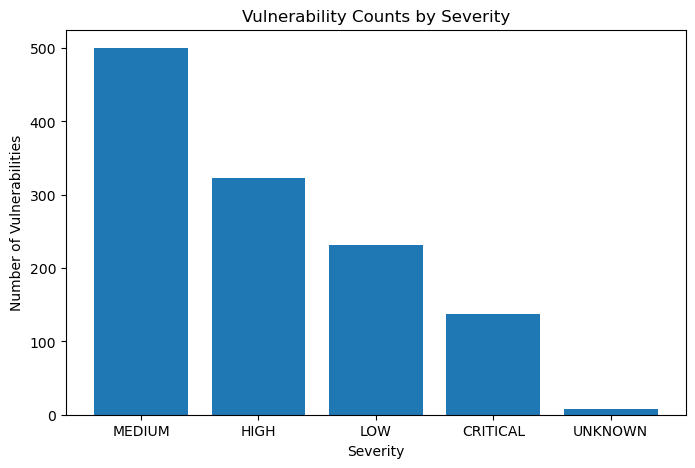

In [66]:
import matplotlib.pyplot as plt

severity_count = df['Severity'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(severity_count.index, severity_count.values)

plt.title('Vulnerability Counts by Severity')
plt.xlabel('Severity')
plt.ylabel('Number of Vulnerabilities')

plt.show()

##  Create a stacked bar chart comparing remediated and unresolved vulnerabilities.

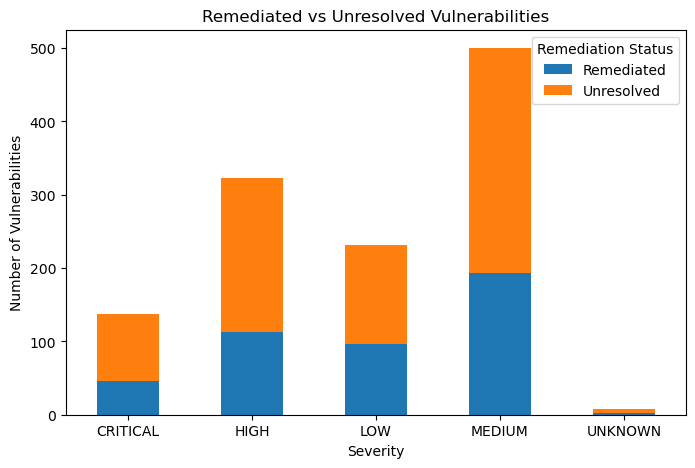

In [67]:
import matplotlib.pyplot as plt

df['Remediation Status'] = df['Patch Status'].apply(
    lambda x: 'Remediated' if x == 'PATCHED' else 'Unresolved'
)

status_count = pd.crosstab(df['Severity'], df['Remediation Status'])

status_count.plot(kind='bar', stacked=True, figsize=(8, 5))

plt.title('Remediated vs Unresolved Vulnerabilities')
plt.xlabel('Severity')
plt.ylabel('Number of Vulnerabilities')
plt.legend(title='Remediation Status')
plt.xticks(rotation=0)
plt.show()

## Create a box plot showing remediation time by severity.

<Figure size 800x500 with 0 Axes>

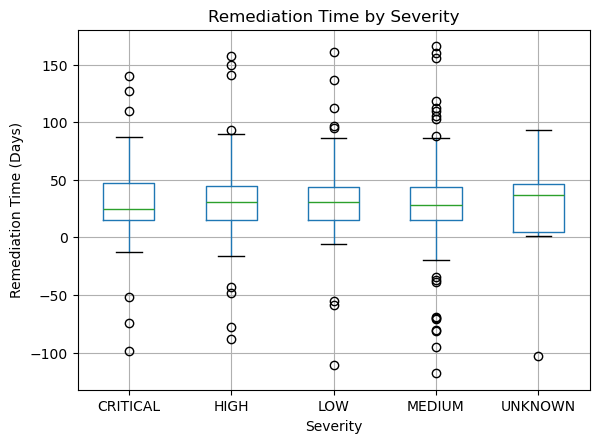

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column='Remediation Time',
    by='Severity'
)

plt.title('Remediation Time by Severity')
plt.suptitle('')
plt.xlabel('Severity')
plt.ylabel('Remediation Time (Days)')
plt.show()